# Machine Learning Laboratory · 01
## Regression, interpolation and population risk

Experiments for **slides L2-S01–L2-S14**. This notebook is self-contained:
run it in a fresh kernel; no earlier notebook or saved result is required.

[All notebooks and setup](NOTEBOOK_README.md) · [Practical exercises](exercises/README.md)

Install `requirements-notebook.txt`, then select **Restart Kernel and Run All Cells**.
The saved static plots and diagnostics can be read on GitHub. Python 3.11+;
CPU / float64. The default seed and target agree with the slides.

**Question:** when fitting noisy samples of $f_\star(x)=\sin(\pi x)$,
why can a predictor with larger training error have smaller prediction error?

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

Matplotlib is building the font cache; this may take a moment.


{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## 1 · A baseline, a curved model and an interpolant

We draw $N=64$ observations with $X\sim\mathrm{Uniform}[0,1]$ and
$Y=f_\star(X)+\varepsilon$, where $\varepsilon\sim\mathcal N(0,\sigma^2)$.
The affine model uses the slide convention $A=[x,1]$, $\beta=[w,b]^T$.
We solve least squares directly, without forming an inverse.

The three methods are fixed before generating assessment data. The cubic uses
Legendre polynomials on $[-1,1]$ for more stable scaling. The piecewise linear
interpolant fits the observed labels exactly and uses constant extension outside
the smallest and largest sampled inputs. Its noisy slopes need not approximate
the smooth signal well.

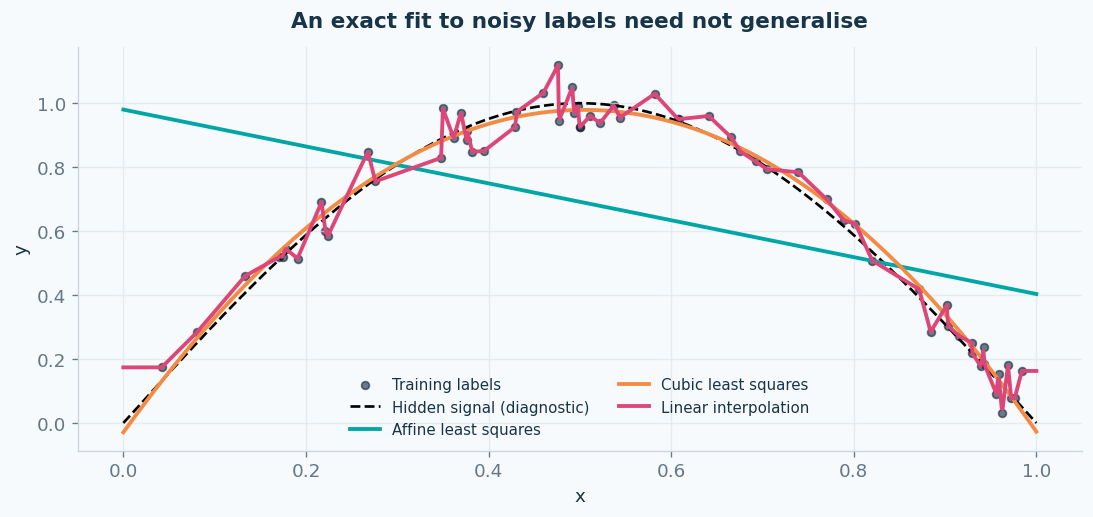

Affine slope -0.576865; intercept 0.980144
Normal-equation residual: 6.71e-15


In [2]:
sigma = 0.05
train_x, train_y = sample_data(rng, 64, sigma)
A = np.column_stack([train_x[:, 0], np.ones(len(train_x))])
beta, *_ = np.linalg.lstsq(A, train_y[:, 0], rcond=None)
normal_residual = np.linalg.norm(A.T @ (A @ beta - train_y[:, 0]))
assert normal_residual < 1e-10

P = np.polynomial.legendre.legvander(2*train_x[:, 0]-1, 3)
cubic_beta, *_ = np.linalg.lstsq(P, train_y[:, 0], rcond=None)
predictors = {
    "Affine least squares": lambda x: beta[0]*np.asarray(x)+beta[1],
    "Cubic least squares": lambda x: np.polynomial.legendre.legval(2*np.asarray(x)-1, cubic_beta),
    "Linear interpolation": lambda x: np.interp(np.asarray(x), train_x[:, 0], train_y[:, 0]),
}
xgrid = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
ax.scatter(train_x, train_y, s=22, color=palette["navy"], alpha=.6, label="Training labels")
ax.plot(xgrid, signal(xgrid), "k--", lw=1.6, label="Hidden signal (diagnostic)")
for name, predict in predictors.items():
    ax.plot(xgrid, predict(xgrid), label=name)
ax.set(xlabel="x", ylabel="y", title="An exact fit to noisy labels need not generalise")
ax.grid(); ax.legend(ncol=2, fontsize=9)
show_figure(fig)
print(f"Affine slope {beta[0]:.6f}; intercept {beta[1]:.6f}")
print(f"Normal-equation residual: {normal_residual:.2e}")

## 2 · Separate fitting error, signal error and label noise

For any predictor fitted using the training data, independent future observations satisfy
$$R(u)=\mathbb E[(u(X)-Y)^2]
=\int_0^1 (u(x)-f_\star(x))^2\,dx+\sigma^2.$$

We know $f_\star$ only because this is a synthetic experiment. Composite midpoint
quadrature estimates the clean integral; a new Monte Carlo sample estimates noisy
risk independently. Neither is used for fitting or choosing the three methods.
A quadrature estimate is not an exact population expectation, and a finite Monte
Carlo estimate need not lie above the noise floor in every run.

Predictor                   train MSE   signal MSE   risk ≈ signal+noise      MC risk
Affine least squares         0.079694      0.12548               0.12798      0.12909
Cubic least squares          0.002586   0.00041834             0.0029183    0.0029891
Linear interpolation                0    0.0023697             0.0048697    0.0049186


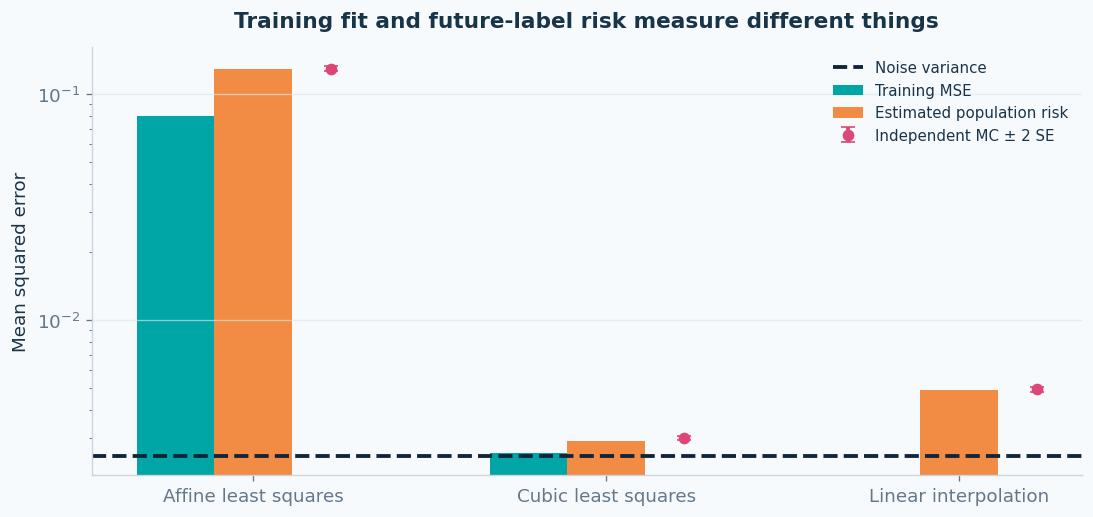

In [3]:
assessment_rng = np.random.default_rng(SEED + 100)
assessment_x, assessment_y = sample_data(assessment_rng, 20000, sigma)
qx = (np.arange(20000)+0.5)/20000
risk_rows = []
print(f"{'Predictor':24s} {'train MSE':>12s} {'signal MSE':>12s} {'risk ≈ signal+noise':>21s} {'MC risk':>12s}")
for name, predict in predictors.items():
    train_mse = np.mean((predict(train_x[:, 0])-train_y[:, 0])**2)
    signal_mse = np.mean((predict(qx)-signal(qx))**2)
    losses = (predict(assessment_x[:, 0])-assessment_y[:, 0])**2
    risk = signal_mse + sigma**2
    mc_risk = np.mean(losses)
    mc_se = np.std(losses, ddof=1)/np.sqrt(len(losses))
    risk_rows.append((name, train_mse, signal_mse, risk, mc_risk, mc_se))
    print(f"{name:24s} {train_mse:12.5g} {signal_mse:12.5g} {risk:21.5g} {mc_risk:12.5g}")
    # A generous numerical smoke check; this is not a theorem about random samples.
    assert abs(risk-mc_risk) < 7*mc_se + 1e-4
assert risk_rows[-1][1] < 1e-25
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
pos = np.arange(len(risk_rows))
ax.bar(pos-.22, [r[1] for r in risk_rows], .22, label="Training MSE")
ax.bar(pos, [r[3] for r in risk_rows], .22, label="Estimated population risk")
ax.errorbar(pos+.22, [r[4] for r in risk_rows], yerr=[2*r[5] for r in risk_rows],
            fmt="o", color=palette["pink"], capsize=4, label="Independent MC ± 2 SE")
ax.axhline(sigma**2, color=palette["navy"], ls="--", label="Noise variance")
ax.set(xticks=pos, xticklabels=[r[0] for r in risk_rows], ylabel="Mean squared error",
       title="Training fit and future-label risk measure different things", yscale="log")
ax.legend(fontsize=9); ax.grid(axis="y")
show_figure(fig)

## 3 · More data cannot remove the error of an affine model

Repeat the affine and cubic fits on independent training datasets of several sizes.
The shaded bands are the 10th–90th percentiles over 40 datasets, **not** confidence
intervals for the mean. We assess the clean signal on the same dense midpoint grid.
More observations reduce variability, but an affine function still cannot represent
$\sin(\pi x)$. This separates finite-sample error from model rigidity.

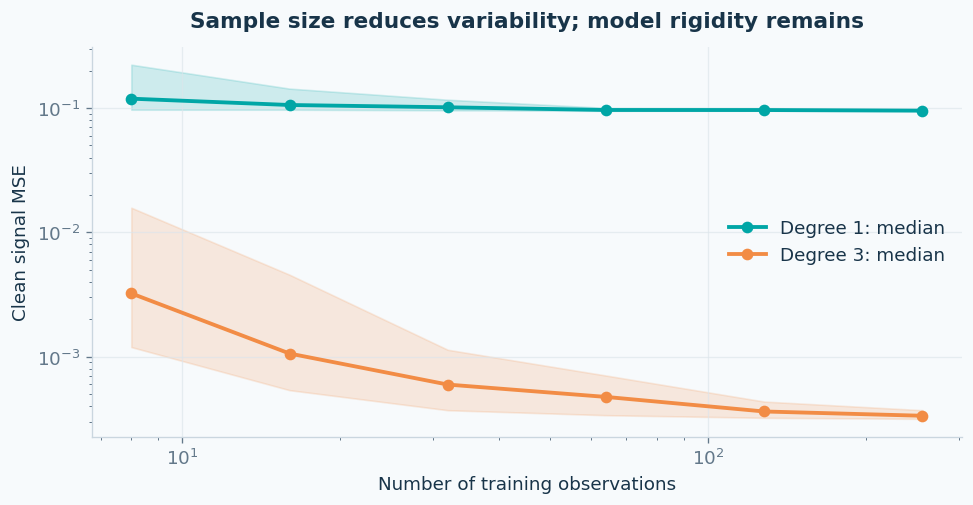

Completed 480 small least-squares fits.
Notebook runtime: 1.5 s


In [4]:
sample_sizes = [8, 16, 32, 64, 128, 256]
repetitions = 40*FACTOR
curve_rng = np.random.default_rng(SEED + 200)
curve_x = (np.arange(2000)+.5)/2000
curves = {degree: [] for degree in [1, 3]}
for n in sample_sizes:
    errors = {1: [], 3: []}
    for repeat in range(repetitions):
        x, y = sample_data(curve_rng, n, sigma)
        for degree in errors:
            design = np.polynomial.legendre.legvander(2*x[:, 0]-1, degree)
            coefficient, *_ = np.linalg.lstsq(design, y[:, 0], rcond=None)
            prediction = np.polynomial.legendre.legval(2*curve_x-1, coefficient)
            errors[degree].append(np.mean((prediction-signal(curve_x))**2))
    for degree in curves:
        curves[degree].append(errors[degree])
fig, ax = plt.subplots(figsize=(8, 4.1), layout="constrained")
for degree, values in curves.items():
    values = np.asarray(values)
    line, = ax.plot(sample_sizes, np.median(values, axis=1), "o-", label=f"Degree {degree}: median")
    lo, hi = np.quantile(values, [.1, .9], axis=1)
    ax.fill_between(sample_sizes, lo, hi, color=line.get_color(), alpha=.17)
ax.set(xscale="log", yscale="log", xlabel="Number of training observations",
       ylabel="Clean signal MSE", title="Sample size reduces variability; model rigidity remains")
ax.legend(); ax.grid()
show_figure(fig)
print(f"Completed {2*len(sample_sizes)*repetitions} small least-squares fits.")
print(f"Notebook runtime: {time.perf_counter()-START:.1f} s")

## Read the evidence

- The affine solver essentially eliminates optimisation error, but not approximation error.
- An interpolant can have zero empirical risk while retaining noise in its predictions.
- Known clean signal error is a synthetic diagnostic; real applications need independent data.

**Try:** increase `sigma`, or repeat with a different seed. Replace the cubic by degrees
2–10, selecting degree on a fresh validation set. Keep the final test set untouched
until that selection is finished. Explain which conclusions are specific to this target.

Continue with [networks and optimisation](ML_02_networks_and_optimisation.ipynb),
or work through [practical 01](exercises/ML_Exercises_01_regression_and_approximation.ipynb).